## EN3160 Assignment 3 on Neural Networks

##### Name : Rasanjana W.P.G.R.A.
##### Index Number : 230536E
Github Link : [https://github.com/rus1ru/EN3160_Assignment_1](https://github.com/rus1ru/EN3160_Assignment_1)

### Q1: 


Files already downloaded and verified
Files already downloaded and verified
Epoch 1/10, Loss: 2.0349625746011735
Epoch 2/10, Loss: 1.781848028421402
Epoch 3/10, Loss: 1.6999282596111298
Epoch 4/10, Loss: 1.6499321044683457
Epoch 5/10, Loss: 1.6086836755275726
Epoch 6/10, Loss: 1.573194182753563
Epoch 7/10, Loss: 1.5436183910369874
Epoch 8/10, Loss: 1.516858021259308
Epoch 9/10, Loss: 1.4924603118896484
Epoch 10/10, Loss: 1.4706135441064834
Training accuracy: 50.29%
Test accuracy: 46.98%


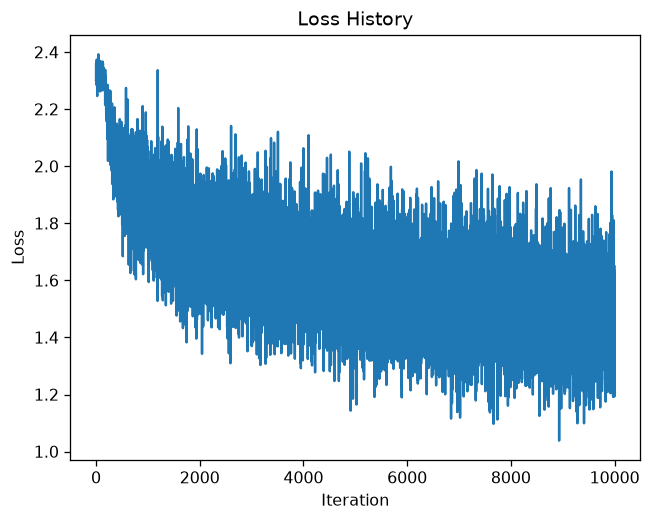

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

torchvision.datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/liangnanying/cifar-10-python/"
    "resolve/main/cifar-10-python.tar.gz"
)

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Hidden layer size
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std  # Weights for the first layer
b1 = torch.zeros(H)            # Biases for the first layer
w2 = torch.randn(H, K) * std   # Weights for the second layer
b2 = torch.zeros(K)            # Biases for the second layer

# Hyperparameters
iterations = 10
lr = 1e-1       # Learning rate
lr_decay = 0.9   # Learning rate decay
reg = 0          # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]                       # Batch size
        x_train = inputs.view(Ntr, -1)              # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass

        # Input -> hidden layer
        z_hidden = x_train.mm(w1) + b1
        hidden = torch.sigmoid(z_hidden)

        # Hidden -> output layer
        y_pred = hidden.mm(w2) + b2

        # Cross-entropy loss from the unnormalized class scores (logits).
        logsumexp = torch.logsumexp(y_pred, dim=1)
        loss = (
            torch.mean(logsumexp - y_pred[torch.arange(Ntr), labels])
            + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation

        # Gradient of cross-entropy with respect to the logits.
        # Manual numerically stable softmax over the class dimension.
        shifted_scores = y_pred - torch.max(y_pred, dim=1, keepdim=True).values
        exp_scores = torch.exp(shifted_scores)
        probabilities = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)
        dy_pred = (probabilities - y_train_onehot) / Ntr

        # Gradients for hidden -> output layer
        dw2 = hidden.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        # Propagate gradient through w2
        dhidden = dy_pred.mm(w2.t())

        # Sigmoid derivative: sigmoid(z) * (1 - sigmoid(z))
        dz_hidden = dhidden * hidden * (1.0 - hidden)

        # Gradients for input -> hidden layer
        dw1 = x_train.t().mm(dz_hidden) + reg * w1
        db1 = dz_hidden.sum(dim=0)

        # Parameter updates
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# Use the same forward pass to measure both splits.
@torch.no_grad()
def accuracy(loader):
    correct = total = 0
    for inputs, labels in loader:
        x = inputs.view(inputs.shape[0], -1)
        hidden = torch.sigmoid(x.mm(w1) + b1)
        predictions = (hidden.mm(w2) + b2).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    return 100 * correct / total

train_acc = accuracy(trainloader)
test_acc = accuracy(testloader)
print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy: {test_acc:.2f}%")


**What the results mean.** The loss curve shows whether mistakes on training batches are getting smaller. Compare training and test accuracy to see how well learning carries over to unseen pictures. A small network that flattens an image can miss patterns formed by nearby pixels.


### Q2: Two ways to recognize handwritten digits

**Idea.** Both networks learn small visual patterns and combine them to recognize digits. We give them the same ten training passes, then compare their learning curves and the digits they confuse.


In [18]:
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import ConfusionMatrixDisplay

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)

transform = transforms.Compose([transforms.Pad(2), transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))])

data = datasets.MNIST("data", train=True, download=True, transform=transform)
train, val = random_split(data, [54000, 6000], generator=torch.Generator().manual_seed(42))

test = datasets.MNIST("data", train=False, download=True, transform=transform)
loaders = [DataLoader(d, batch_size=128) for d in [train, val, test]]


In [19]:
lenet = nn.Sequential(
    nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
    nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),
    nn.Conv2d(16, 120, 5), nn.Tanh(), nn.Flatten(),
    nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))

cnn = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1, bias=False),
    nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1, bias=False),
    nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1, bias=False),
    nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d(4),
    nn.Flatten(), nn.Dropout(0.3), nn.Linear(1024, 10))


In [20]:
loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss, correct, actual, predicted = 0, 0, [], []
    for x, y in loader:
        output = model(x.to(device))
        loss += loss_fn(output, y.to(device)).item() * len(y)
        pred = output.argmax(1).cpu()
        correct += (pred == y).sum().item()
        actual.extend(y.tolist())
        predicted.extend(pred.tolist())
    return loss / len(loader.dataset), 100 * correct / len(loader.dataset), actual, predicted


In [21]:
results = {}
for name, model in [("LeNet5", lenet), ("ModernCNN", cnn)]:
    batches = DataLoader(train, batch_size=128, shuffle=True,
                         generator=torch.Generator().manual_seed(42))
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = []
    print("\n" + name)
    for epoch in range(10):
        model.train()
        for x, y in batches:
            optimizer.zero_grad()
            loss_fn(model(x.to(device)), y.to(device)).backward()
            optimizer.step()
        metrics = [evaluate(model, loader)[:2] for loader in loaders]
        history.append(metrics)  # Train, validation, test: (loss, accuracy)
        print(f"Epoch {epoch+1}: " + " | ".join(
            f"{label} loss {m[0]:.4f}, acc {m[1]:.2f}%"
            for label, m in zip(["Train", "Val", "Test"], metrics)))
    test_score = evaluate(model, loaders[2])
    results[name] = (history, test_score)
    print(f"Epoch 10: Train {history[-1][0][1]:.2f}% | Test {test_score[1]:.2f}%")



LeNet5
Epoch 1: Train loss 0.1194, acc 96.50% | Val loss 0.1292, acc 96.22% | Test loss 0.1189, acc 96.57%
Epoch 2: Train loss 0.0612, acc 98.16% | Val loss 0.0753, acc 97.97% | Test loss 0.0650, acc 97.94%
Epoch 3: Train loss 0.0475, acc 98.53% | Val loss 0.0603, acc 98.28% | Test loss 0.0522, acc 98.33%
Epoch 4: Train loss 0.0371, acc 98.85% | Val loss 0.0577, acc 98.23% | Test loss 0.0505, acc 98.38%
Epoch 5: Train loss 0.0281, acc 99.14% | Val loss 0.0505, acc 98.57% | Test loss 0.0471, acc 98.54%
Epoch 6: Train loss 0.0247, acc 99.24% | Val loss 0.0492, acc 98.63% | Test loss 0.0411, acc 98.68%
Epoch 7: Train loss 0.0179, acc 99.49% | Val loss 0.0441, acc 98.78% | Test loss 0.0362, acc 98.84%
Epoch 8: Train loss 0.0168, acc 99.51% | Val loss 0.0425, acc 98.78% | Test loss 0.0417, acc 98.73%
Epoch 9: Train loss 0.0152, acc 99.56% | Val loss 0.0438, acc 98.78% | Test loss 0.0391, acc 98.85%
Epoch 10: Train loss 0.0121, acc 99.67% | Val loss 0.0410, acc 98.78% | Test loss 0.0358, ac

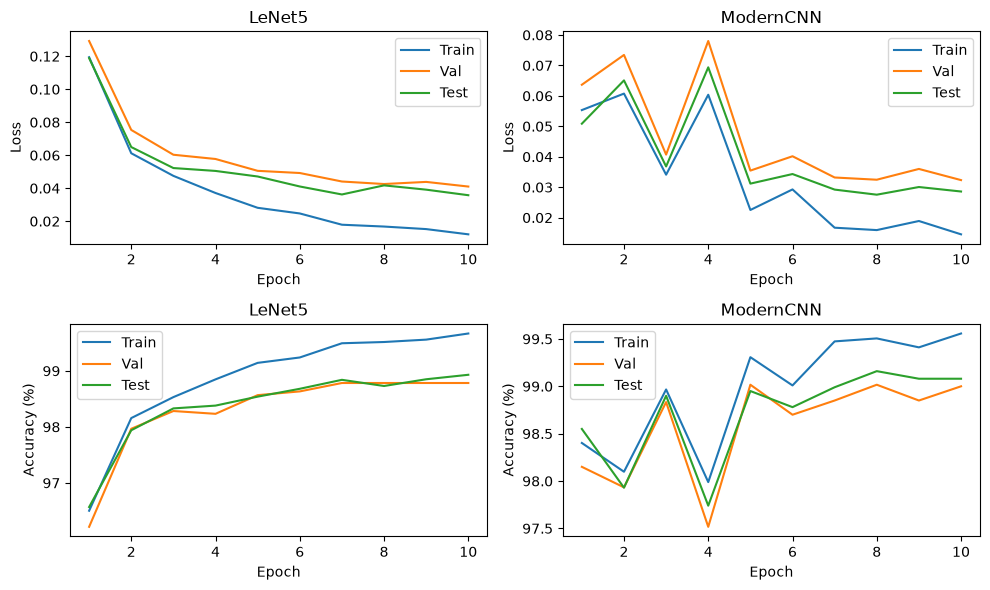

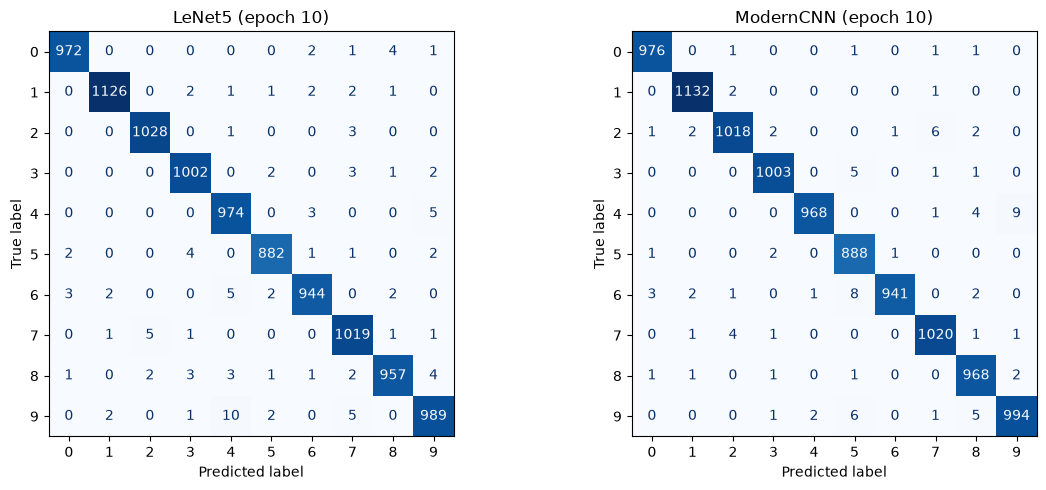

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for col, (name, (history, score)) in enumerate(results.items()):
    for row, ylabel in enumerate(["Loss", "Accuracy (%)"]):
        for split, label in enumerate(["Train", "Val", "Test"]):
            axes[row, col].plot(range(1, len(history)+1),
                [epoch[split][row] for epoch in history], label=label)
        axes[row, col].set(title=name, xlabel="Epoch", ylabel=ylabel)
        axes[row, col].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (history, score)) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(score[2], score[3], labels=range(10),
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name + " (epoch 10)")
plt.tight_layout()
plt.show()


**What the results mean.** Compare the test accuracy at the end of ten passes. In a confusion matrix, most counts should lie on the diagonal: those are correct answers. Counts away from it show which digits were mixed up. The validation images help us watch learning without changing the test images.


### Q3: Starting from a network that already recognizes images

**Idea.** ResNet18 learned useful visual patterns from many other images. We try two ways to reuse it for ants and bees. Fine-tuning adjusts the whole network; feature extraction keeps most of it fixed and teaches only the last decision layer.


In [23]:
from pathlib import Path
from torchvision.datasets.utils import download_and_extract_archive

data_dir = Path("data/hymenoptera_data")

if not data_dir.exists():
    download_and_extract_archive(
        url="https://download.pytorch.org/tutorial/hymenoptera_data.zip",
        download_root="data"
    )

In [24]:
from torchvision import datasets, transforms
from torchvision import models

weights = models.ResNet18_Weights.IMAGENET1K_V1
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ]),
    "val": weights.transforms()
}

In [25]:
import torch

image_datasets = {
    phase: datasets.ImageFolder(
        data_dir / phase,
        transform=data_transforms[phase]
    )
    for phase in ["train", "val"]
}

dataloaders = {
    phase: torch.utils.data.DataLoader(
        image_datasets[phase],
        batch_size=4,
        shuffle=(phase == "train"),
        num_workers=0
    )
    for phase in ["train", "val"]
}

print("Classes:", image_datasets["train"].classes)
print("Training images:", len(image_datasets["train"]))
print("Validation images:", len(image_datasets["val"]))


Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


In [26]:
import torch.nn as nn

# Both runs start with ImageNet-pretrained ResNet18 and a new two-class head.
model_ft = models.resnet18(weights=weights)
model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)

model_fe = models.resnet18(weights=weights)
for parameter in model_fe.parameters():
    parameter.requires_grad = False
model_fe.fc = nn.Linear(model_fe.fc.in_features, 2)


In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_ft = model_ft.to(device)
model_fe = model_fe.to(device)

criterion = nn.CrossEntropyLoss()

# Fine-tuning: update every layer
optimizer_ft = torch.optim.SGD(
    model_ft.parameters(),
    lr=0.001,
    momentum=0.9
)

# Feature extraction: update only the new classifier
optimizer_fe = torch.optim.SGD(
    model_fe.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

In [28]:
import copy
import time

def train_model(model, optimizer, feature_extractor=False, epochs=25):
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=7, gamma=0.1
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_acc = -1.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(epochs):
        for phase in ["train", "val"]:
            training = phase == "train"

            if training and not feature_extractor:
                model.train()
            else:
                model.eval()
                if training:
                    model.fc.train()

            total_loss = 0.0
            correct = 0
            total = 0

            for images, labels in dataloaders[phase]:
                images = images.to(device)
                labels = labels.to(device)

                if training:
                    optimizer.zero_grad()

                with torch.set_grad_enabled(training):
                    logits = model(images)
                    loss = criterion(logits, labels)

                    if training:
                        loss.backward()
                        optimizer.step()

                total_loss += loss.item() * labels.size(0)
                correct += (logits.argmax(dim=1) == labels).sum().item()
                total += labels.size(0)

            epoch_loss = total_loss / total
            epoch_acc = correct / total

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_epoch = epoch + 1
                best_weights = copy.deepcopy(model.state_dict())

        scheduler.step()

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train loss: {history['train_loss'][-1]:.4f} | "
            f"Train acc: {history['train_acc'][-1]:.2%} | "
            f"Val loss: {history['val_loss'][-1]:.4f} | "
            f"Val acc: {history['val_acc'][-1]:.2%}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    model.load_state_dict(best_weights)
    model.eval()

    print(f"\nBest validation accuracy: {best_acc:.2%}")
    print(f"Best epoch: {best_epoch}")
    print(f"Training + validation time: {elapsed:.1f} seconds")

    return model, history, {
        "best_val_acc": best_acc,
        "best_epoch": best_epoch,
        "seconds": elapsed
    }

In [29]:
model_ft, history_ft, results_ft = train_model(
    model_ft, optimizer_ft
)


Epoch 01/25 | Train loss: 0.7568 | Train acc: 62.70% | Val loss: 0.3322 | Val acc: 88.89%
Epoch 02/25 | Train loss: 0.7317 | Train acc: 76.23% | Val loss: 0.2642 | Val acc: 91.50%
Epoch 03/25 | Train loss: 0.4666 | Train acc: 81.97% | Val loss: 0.3132 | Val acc: 89.54%
Epoch 04/25 | Train loss: 0.6029 | Train acc: 76.64% | Val loss: 0.4576 | Val acc: 84.97%
Epoch 05/25 | Train loss: 0.5607 | Train acc: 77.87% | Val loss: 0.2195 | Val acc: 90.85%
Epoch 06/25 | Train loss: 0.6677 | Train acc: 74.59% | Val loss: 0.4294 | Val acc: 82.35%
Epoch 07/25 | Train loss: 0.3430 | Train acc: 84.43% | Val loss: 0.2043 | Val acc: 92.81%
Epoch 08/25 | Train loss: 0.3214 | Train acc: 86.07% | Val loss: 0.1978 | Val acc: 94.12%
Epoch 09/25 | Train loss: 0.3669 | Train acc: 86.07% | Val loss: 0.2618 | Val acc: 90.20%
Epoch 10/25 | Train loss: 0.2995 | Train acc: 86.07% | Val loss: 0.2160 | Val acc: 94.12%
Epoch 11/25 | Train loss: 0.2829 | Train acc: 87.70% | Val loss: 0.1796 | Val acc: 94.77%
Epoch 12/2

In [30]:
model_fe, history_fe, results_fe = train_model(
    model_fe, optimizer_fe, feature_extractor=True
)

Epoch 01/25 | Train loss: 0.3170 | Train acc: 85.25% | Val loss: 0.1746 | Val acc: 93.46%
Epoch 02/25 | Train loss: 0.1485 | Train acc: 92.62% | Val loss: 0.1344 | Val acc: 96.08%
Epoch 03/25 | Train loss: 0.1083 | Train acc: 95.90% | Val loss: 0.1382 | Val acc: 95.42%
Epoch 04/25 | Train loss: 0.1394 | Train acc: 93.85% | Val loss: 0.1848 | Val acc: 95.42%
Epoch 05/25 | Train loss: 0.1498 | Train acc: 93.03% | Val loss: 0.1553 | Val acc: 96.08%
Epoch 06/25 | Train loss: 0.0914 | Train acc: 96.72% | Val loss: 0.1894 | Val acc: 95.42%
Epoch 07/25 | Train loss: 0.0998 | Train acc: 96.72% | Val loss: 0.1595 | Val acc: 95.42%
Epoch 08/25 | Train loss: 0.0644 | Train acc: 98.77% | Val loss: 0.1609 | Val acc: 95.42%
Epoch 09/25 | Train loss: 0.0686 | Train acc: 97.54% | Val loss: 0.1622 | Val acc: 95.42%
Epoch 10/25 | Train loss: 0.0675 | Train acc: 97.95% | Val loss: 0.1626 | Val acc: 95.42%
Epoch 11/25 | Train loss: 0.1009 | Train acc: 95.08% | Val loss: 0.1626 | Val acc: 95.42%
Epoch 12/2

**What the results mean.** The figure compares the two approaches on images held aside for validation. A higher training score alone would not prove better performance on new pictures. There is no separate test set in this experiment, and the small validation set can make results change between runs.


Fine-tuning: best validation accuracy 94.77% (epoch 11), 63.2 s
Feature extraction: best validation accuracy 96.08% (epoch 2), 56.7 s


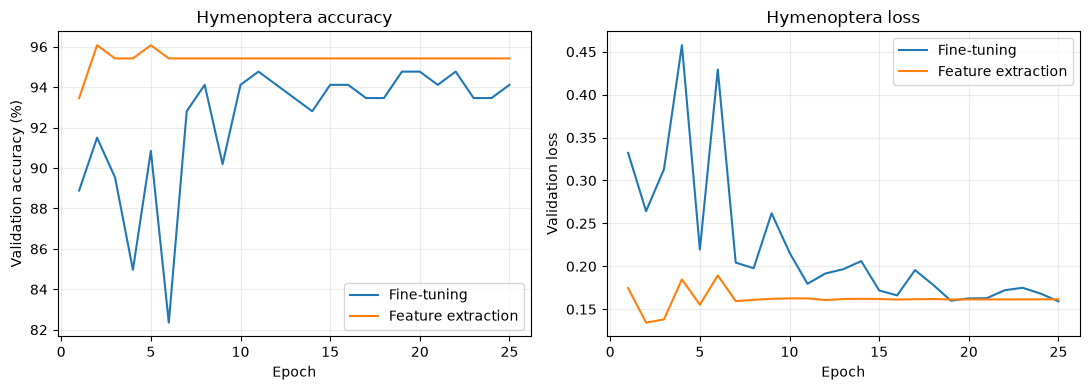

In [31]:
# Compare transfer-learning methods using the validation split (not a test set).
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, history, summary in [
    ("Fine-tuning", history_ft, results_ft),
    ("Feature extraction", history_fe, results_fe),
]:
    epochs = range(1, len(history["val_acc"]) + 1)
    axes[0].plot(epochs, [100 * acc for acc in history["val_acc"]], label=label)
    axes[1].plot(epochs, history["val_loss"], label=label)
    print(f"{label}: best validation accuracy {summary['best_val_acc']:.2%} "
          f"(epoch {summary['best_epoch']}), {summary['seconds']:.1f} s")
axes[0].set(xlabel="Epoch", ylabel="Validation accuracy (%)", title="Hymenoptera accuracy")
axes[1].set(xlabel="Epoch", ylabel="Validation loss", title="Hymenoptera loss")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
